# Heston calibrated maturity by maturity

**TFG (BSc in Economics, Universitat Pompeu Fabra)** · Carles Aliern Fons · supervisor: Elisa Alòs

**Question.** Which Heston parameters fit each maturity, and how do they change with maturity?

**What this notebook does**

| Section | What it does |
|---|---|
| 0 | Setup (libraries, versions) |
| 1 | Data of the day: where they come from and how implied volatilities are computed |
| 2 | **Global** calibration (all maturities at once), as in the ATM skew notebook: the benchmark |
| 3 | Tools to calibrate **a single maturity** |
| 4 | **Case A**: the 5 parameters free at each maturity → the *identification problem* |
| 5 | **Case B**: κ and θ fixed, we calibrate ν, ρ, v0 at each maturity. **Case C**: v0 fixed too, we calibrate only ν and ρ |
| 6 | Does the same pattern appear on the other days we have downloaded? |
| 7 | **Case D** (only ν free) and **case E** (only ρ free): which of the two parameters fits the *smile*? |
| 8 | Conclusions and references |

**How to run it:** in VS Code, *Run All*; or, in a terminal opened in this folder:

`py -m nbconvert --to notebook --execute --inplace calibration_by_maturity.ipynb`

It takes about 35 minutes on a laptop (case A, cases B to E and section 6 are the slow parts).

**Notation:** K = strike, F = forward, k = ln(K/F) (*log-moneyness*: k < 0 are out-of-the-money puts, k > 0 out-of-the-money calls), T = maturity in years, "volatility points" = volatility × 100 (for example, 0.15 → 15 points). Heston parameters: κ (speed of mean reversion), θ (long-run variance), ν (volatility of volatility), ρ (correlation between price and volatility), v0 (today's variance).

## 0. Setup

In [1]:
# --- Libraries ---
import os                                     # to build file paths that work on Windows and on Linux
import sys                                    # to know the Python version (reproducibility)
import time                                   # to measure how long each step takes
import numpy as np                            # numerical computation with vectors
import pandas as pd                           # data tables (DataFrame)
import scipy                                  # only to print its version
import matplotlib                             # only to print its version
import matplotlib.pyplot as plt               # plots
from scipy.optimize import least_squares      # non-linear least squares (the same optimiser that ht.calibrate uses)
import heston_tfg as ht                       # our library (the same as in the ATM Skew folder)

# --- Display options ---
pd.set_option("display.width", 220)           # wide tables, without breaking lines
pd.set_option("display.max_columns", 30)      # show all columns
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False, "legend.frameon": False, "figure.dpi": 110})  # plot style

# --- Parameters of the analysis ---
DATA_FOLDER = os.path.join("..", "Data")      # the daily data are in ..\Data, one subfolder per day
DAY = "2026-10-12"                            # main day of the analysis

# --- Versions: with these versions anybody should obtain exactly the same numbers ---
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)

Python 3.12.10 | numpy 2.5.3 | scipy 1.18.1 | pandas 3.0.6 | matplotlib 3.11.2


## 1. Data

**Where they come from.** Every weekday after the close of the US market the program `Data\download_daily.py` downloads from **Yahoo Finance** (with the Python package `yfinance`) all the options on the S&P 500 index (`^SPX`) and on the SPY ETF, and saves them in `Data\YYYY-MM-DD\`. For each option we have the price at which someone is willing to buy (*bid*), the price at which someone is willing to sell (*ask*), the last traded price, the volume, the *open interest*, the expiry and the strike. The file `market.csv` stores the index price (*spot*), the VIX and the yield of the 13-week US Treasury bill (`^IRX`), which we use as the risk-free rate r.

**We compute the implied volatilities ourselves.** Yahoo also gives one (column `impliedVolatility`), but it does not document how it is computed, so we do not use it. For each maturity, the function `ht.build_clean_chain` does the following:
1. Price of each option = midpoint between bid and ask.
2. Forward F from put-call parity, C − P = e^(−rT)(F − K), with the 3 strikes closest to the index price. This way dividends do not need to be known.
3. We keep only **out-of-the-money** options (puts if K < F, calls if K ≥ F), because they are the most traded. Puts are converted into calls with the same parity.
4. Implied volatility = the σ that makes the Black-76 formula (Black-Scholes written with the forward) give exactly the market price. There is no closed formula: it is found numerically (Brent's method).
5. Quality filters: we remove spreads that are too wide, prices that are too small, options with very small vega and points that jump with respect to their neighbours.

**SPX and SPXW.** S&P 500 options have two "roots" (the first letters of the contract code): **SPXW** expire at the **close** of the day (*PM-settled*) and **SPX**, the classic monthly ones, expire at the **open** of the third Friday (*AM-settled*), about 6.5 hours earlier. When a maturity has both, we keep SPXW so that all maturities are measured in the same way. We only use SPX for the long maturities where there is no SPXW (there, 6.5 hours of difference do not matter).

**Which maturities.** Every day there are about 50 maturities. We use the same target horizons as in the ATM skew notebook (2, 4, 7, 10, 14, 21, 30, 45, 60, 90, 120, 180, 270 and 365 days) and, for each horizon, among the maturities within ±15% of days we choose the one with the most options with bid and ask, that is, the most **liquid** one.

In [2]:
def load_day(day, folder=DATA_FOLDER, show=True):
    """Reads the data of one day of the daily download and returns (spot, r, clean SPX chain)."""
    # 1) Files of the day: the SPX option chain (compressed) and the market data
    raw = pd.read_csv(os.path.join(folder, day, "SPX.csv.gz"))            # one row per option
    market = pd.read_csv(os.path.join(folder, day, "market.csv"))          # a single row
    spot = float(market["spot_SPX"].iloc[0])                               # index price at the close
    r = float(market["IRX_13w_tbill_pct"].iloc[0]) / 100                   # ^IRX comes in %, we turn it into a decimal
    # 2) Days to expiry. Column T is in years (calendar days / 365)
    raw["days"] = (raw["T"] * 365).round().astype(int)                    # rounded to avoid decimals such as 6.9999
    raw = raw[raw["days"] >= 2]                                            # out: those expiring today or tomorrow (too noisy)
    # 3) Root of the contract: the code is ROOT + YYMMDD + C/P + 8 digits of the strike, and the last 15 characters are fixed
    raw["root"] = raw["contractSymbol"].str[:-15]                          # e.g. "SPXW261016C07800000" -> "SPXW"
    has_spxw = raw.groupby("expiry")["root"].transform(lambda s: (s == "SPXW").any())  # does this maturity have SPXW?
    raw = raw[(raw["root"] == "SPXW") | ~has_spxw]                         # SPXW if there is any; otherwise SPX
    # 4) Liquidity: how many options of each maturity have a valid bid and ask
    valid = (raw["bid"] > 0) & (raw["ask"] > raw["bid"])                   # live and coherent quote
    n_valid = raw[valid].groupby("days").size()                           # series: days -> number of valid options
    # 5) For each target horizon, the most liquid maturity within ±15% (±1 day for the very short ones)
    chosen = []
    for t in ht.TARGET_DAYS:                                               # 2, 4, 7, ..., 365 days
        candidates = n_valid[(n_valid.index >= 0.85 * t - 1) & (n_valid.index <= 1.15 * t + 1)]
        if len(candidates) == 0:                                           # if there is none within ±15%...
            candidates = n_valid.iloc[[np.argmin(np.abs(n_valid.index - t))]]   # ...the closest one
        chosen.append(int(candidates.idxmax()))                            # the one with the most valid options
    chosen = sorted(set(chosen))                                           # without repetitions and sorted
    raw = raw[raw["days"].isin(chosen)]
    # 6) Forward, out-of-the-money options, implied volatilities and filters (library)
    chain = ht.build_clean_chain(raw, spot, r=r)
    if show:
        print(f"Day {day}: SPX spot = {spot:.2f}, r = {r:.4f}, VIX = {float(market['VIX'].iloc[0]):.2f}")
        print(f"Maturities chosen (days): {chosen}")
        print("Cleaning (options removed at each step):", chain.attrs["cleaning"])
    return spot, r, chain


spot, r, chain = load_day(DAY)                                             # we load the main day

# Summary per maturity: forward, number of options, range of k and ATM implied volatility (interpolated at k = 0)
summary = []
for T, g in chain.groupby("T"):
    k = np.log(g["K"] / g["F"]).values                                     # log-moneyness of each option
    summary.append(dict(days=round(T * 365), expiry=g["expiry"].iloc[0], F=round(g["F"].iloc[0], 1),
                        n=len(g), k_min=k.min().round(3), k_max=k.max().round(3),
                        iv_ATM=round(100 * float(np.interp(0.0, k, g["iv"].values)), 2)))
pd.DataFrame(summary)

Day 2026-10-12: SPX spot = 7807.24, r = 0.0405, VIX = 15.21
Maturities chosen (days): [3, 4, 7, 11, 18, 25, 49, 67, 80, 109, 170, 261, 353]
Cleaning (options removed at each step): {'options_before': 2192, 'last_price_quotes': 1, 'low_vega': 5, 'iv_outliers': 15, 'options_after': 2171}


,days,expiry,F,n,k_min,k_max,iv_ATM
0,3,2026-10-15,7808.8,103,-0.088,0.018,10.61
1,4,2026-10-16,7811.4,44,-0.111,0.028,10.76
2,7,2026-10-19,7812.2,115,-0.131,0.033,9.18
3,11,2026-10-23,7817.2,145,-0.185,0.045,10.00
4,18,2026-10-30,7822.6,280,-0.249,0.086,11.25
5,25,2026-11-06,7828.4,104,-0.159,0.076,11.96
6,49,2026-11-30,7842.7,206,-0.235,0.115,12.29
7,67,2026-12-18,7856.0,45,-0.189,0.043,13.10
8,80,2026-12-31,7868.5,400,-0.247,0.145,13.12
9,109,2027-01-29,7897.4,117,-0.214,0.097,13.58


## 2. Global calibration (the benchmark)

We calibrate the 5 parameters with **all maturities at once**, as in the ATM skew notebook. To go faster, and so that no maturity weighs more just because it has more strikes, we keep at most 40 options per maturity (`ht.thin_chain`).

The objective that `ht.calibrate` minimises is Σ((model price − market price)/vega)². Why divide by the vega? Because, if the error is small, price(σ + Δσ) ≈ price(σ) + vega·Δσ, that is, (model price − market price)/vega ≈ σ_model − σ_market: it is approximately the error in implied volatility. It tries 3 starting points and keeps the best one.

In [3]:
t0 = time.time()                                                           # we start the clock
cal = ht.thin_chain(chain, max_per_T=40)                                   # at most 40 options per maturity
pg, global_fit, rmse_global = ht.calibrate(cal, r)                         # global calibration (Fourier, 3 starts)
print(f"\nTime: {time.time() - t0:.0f} s")
print("Global parameters:", {k: round(v, 4) for k, v in pg.items()})
print(f"Error (RMSE) in implied volatility: {100 * rmse_global:.2f} points")
print(f"Feller: 2κθ − ν² = {ht.feller(pg):.3f};  ratio 2κθ/ν² = {2 * pg['kappa'] * pg['theta'] / pg['nu']**2:.3f}"
      "  (the condition holds if the ratio is > 1)")

[fourier] start [ 2.     0.04   0.5   -0.7    0.129] -> cost 0.035277  params [ 9.543  0.0386  1.9396 -0.605   0.0096]
[fourier] start [ 1.     0.06   0.3   -0.5    0.129] -> cost 0.035277  params [ 9.5392  0.0386  1.9393 -0.6051   0.0096]
[fourier] start [ 5.     0.04   1.    -0.8    0.129] -> cost 0.035277  params [ 9.5418  0.0386  1.9395 -0.605   0.0096]

Time: 249 s
Global parameters: {'kappa': 9.543, 'theta': 0.0386, 'nu': 1.9396, 'rho': -0.605, 'v0': 0.0096}
Error (RMSE) in implied volatility: 2.08 points
Feller: 2κθ − ν² = -3.025;  ratio 2κθ/ν² = 0.196  (the condition holds if the ratio is > 1)


## 3. Tools to calibrate a single maturity

Four new ideas with respect to `ht.calibrate`:

**(a) Implied volatility of many strikes at once (bisection).** The library function `ht.implied_vol_fwd` solves one option at a time (Brent's method) and is slow if it has to be called thousands of times. Here we use **bisection**, which is the simplest method: we know that the σ we are looking for is between 0.0001 and 5; we look at the midpoint; if the Black-76 price with this σ is too high, the right σ is in the left half, and otherwise in the right half. After 60 steps the interval measures 5/2⁶⁰ ≈ 4·10⁻¹⁸, that is, we have the exact σ. It works because the price of a call is increasing in σ. We do it for all strikes at once with numpy vectors (about 10 times faster).

**(b) Exact error in implied volatility.** With a single maturity we can afford to minimise Σ(σ_model − σ_market)² directly, without the vega approximation. The approximation is a first-order Taylor expansion and fails when the error is large and the vega changes very quickly, which is what happens in the wings of the short maturities. We check it in the second cell of this section. An important detail: sometimes the model gives a price slightly below the intrinsic value (a tiny numerical error when the price is almost zero) and the implied volatility does not exist. If we put NaN in those cases, the objective function jumps and the optimiser can get stuck (this happened while the notebook was being tested). That is why, for calibrating, the bisection returns the end of the interval (σ = 0.0001), which is the continuous limit: the error is large but the function does not jump.

**(c) Fixed and free parameters, and several starting points.** The function receives a dictionary `fixed` (for example `{"kappa": 9.5, "theta": 0.04}`) and calibrates only the rest. The optimiser only finds the minimum **closest** to the starting point (a *local* minimum), so we try several starts and keep the best one.

**(d) Standard errors, as in econometrics.** In non-linear least squares, Var(parameters) ≈ s²·(JᵀJ)⁻¹, where J is the matrix of derivatives of the residuals with respect to each parameter (the *Jacobian*) and s² = sum of squared residuals / (n − p). It is the same formula as for OLS, s²(XᵀX)⁻¹, with J instead of X. A huge standard error means that the data **do not identify** that parameter. Careful: market errors are not independent noise, so these standard errors are only indicative (see Greene, *Econometric Analysis*, chapter on non-linear regression).

In [4]:
def iv_bisection(price, F, K, T, r, n_iter=60, nan_outside=True):
    """Black-76 implied volatility for many strikes at once, by the bisection method.
    price: call prices (vector), K: strikes (vector).
    nan_outside=True: NaN if the price violates the no-arbitrage bounds. nan_outside=False: in that case it returns
    the end of the interval (0.0001 or 5), which is the continuous limit of the volatility as the price approaches it."""
    price, K = np.asarray(price, float), np.asarray(K, float)              # we work with numpy vectors
    low = np.full(len(K), 1e-4)                                            # lower end of the interval of each strike
    high = np.full(len(K), 5.0)                                            # upper end (500% volatility)
    for _ in range(n_iter):                                                # each step halves the interval
        mid = 0.5 * (low + high)                                           # midpoint
        too_high = ht.bs_call_fwd(F, K, T, mid, r) > price                 # with this σ, is the Black-76 price too high?
        high = np.where(too_high, mid, high)                               # yes: the right σ is on the left -> lower the upper end
        low = np.where(too_high, low, mid)                                 # no: the right σ is on the right -> raise the lower end
    iv = 0.5 * (low + high)                                                # result: the centre of the final interval
    if not nan_outside:                                                    # for calibrating: without NaN, the function does not jump
        return iv
    discount = np.exp(-r * T)                                              # discount factor e^(-rT)
    outside = (price <= discount * np.maximum(F - K, 0) + 1e-12 * F) | (price >= discount * F - 1e-12 * F)
    iv[outside] = np.nan                                                   # impossible price (below the intrinsic value or above F)
    return iv


# Check: the bisection must give the same as the library's Brent method
g = cal[cal["T"] == cal["T"].unique()[5]]                                  # any maturity
prices = g["call_mid"].values                                              # market prices (in call form)
brent = np.array([ht.implied_vol_fwd(c, g["F"].iloc[0], k, g["T"].iloc[0], r) for c, k in zip(prices, g["K"])])
bisec = iv_bisection(prices, g["F"].iloc[0], g["K"].values, g["T"].iloc[0], r)
print(f"Maximum difference Brent vs bisection: {np.nanmax(np.abs(brent - bisec)):.1e}  (must be ~0)")

Maximum difference Brent vs bisection: 1.3e-13  (must be ~0)


In [5]:
# Why don't we use (model price − market price)/vega as the error? Let us look at the ~7-day maturity with the global parameters
T7 = min(cal["T"].unique(), key=lambda T: abs(T * 365 - 7))                # the maturity closest to 7 days
g = cal[cal["T"] == T7]                                                    # its options
F7, K7 = g["F"].iloc[0], g["K"].values                                     # forward and strikes
model_price = ht.heston_call_fwd(F7, K7, T7, r, pg["kappa"], pg["theta"], pg["nu"], pg["rho"], pg["v0"])  # Heston (Fourier)
exact_error = iv_bisection(model_price, F7, K7, T7, r) - g["iv"].values    # σ_model − σ_market
approx_error = (model_price - g["call_mid"].values) / g["vega"].values     # first-order approximation with the vega
table = pd.DataFrame({"k": np.log(K7 / F7), "iv_market": 100 * g["iv"].values,
                      "exact_error": 100 * exact_error, "vega_approx_error": 100 * approx_error})
print(f"Maturity of {round(T7 * 365)} days, in volatility points (the 5 leftmost options and the 5 closest to k = 0):")
pd.concat([table.head(5), table.iloc[(table["k"].abs()).argsort()[:5]].sort_values("k")]).round(2)

Maturity of 7 days, in volatility points (the 5 leftmost options and the 5 closest to k = 0):


,k,iv_market,exact_error,vega_approx_error
0,-0.13,34.36,-7.00,-3.17
1,-0.11,30.06,-4.81,-2.70
2,-0.08,23.45,-1.42,-1.19
3,-0.06,19.28,0.55,0.59
4,-0.05,17.33,1.35,1.60
24,-0.00,9.59,0.62,0.63
25,-0.00,9.40,0.35,0.35
26,-0.00,9.20,0.09,0.09
27,0.00,9.04,-0.17,-0.17
28,0.00,8.89,-0.38,-0.38


In [6]:
# Typical scale of each parameter: it helps the optimiser take steps of reasonable size (like x_scale in ht.calibrate)
SCALE = {"kappa": 1.0, "theta": 0.05, "nu": 0.3, "rho": 0.3, "v0": 0.05}


def calibrate_maturity(g, r, fixed, starts):
    """Calibrates Heston with the options of ONE single maturity.
    g: rows of the chain for this maturity; fixed: {parameter: value} that are not touched;
    starts: list of dictionaries with starting points (their free parameters are used).
    Returns (parameters, standard errors, RMSE in volatility, list of parameters that hit a bound)."""
    free = [n for n in ht.PARAM_NAMES if n not in fixed]                   # the ones we will look for
    pos = [ht.PARAM_NAMES.index(n) for n in free]                          # their position in the list of 5 (for the bounds)
    F, T = g["F"].iloc[0], g["T"].iloc[0]                                  # forward and maturity (common to the whole maturity)
    K = g["K"].values                                                      # strikes
    iv_market = g["iv"].values                                             # market implied volatilities

    def full(x):                                                           # joins fixed + free into a dictionary of 5
        p = dict(fixed)
        p.update(zip(free, x))
        return p

    def residuals(x):                                                      # the vector that least_squares makes small
        p = full(x)
        prices = ht.heston_call_fwd(F, K, T, r, p["kappa"], p["theta"], p["nu"], p["rho"], p["v0"])  # Heston by Fourier
        return iv_bisection(prices, F, K, T, r, nan_outside=False) - iv_market  # exact error in implied volatility (no NaN)

    sol = None
    for start in starts:                                                   # we try each starting point...
        x0 = np.array([start[n] for n in free])                            # starting point (only the free ones)
        x0 = np.clip(x0, ht.LOWER[pos] + 1e-6, ht.UPPER[pos] - 1e-6)       # we make sure it is within the bounds
        trial = least_squares(residuals, x0, bounds=(ht.LOWER[pos], ht.UPPER[pos]), x_scale=[SCALE[n] for n in free])
        if sol is None or trial.cost < sol.cost:                           # ...and keep the one with the smallest error
            sol = trial
    # Standard errors: Var ≈ s² (JᵀJ)⁻¹
    J = sol.jac                                                            # Jacobian at the minimum: (number of options) × (free parameters)
    n, p = J.shape
    s2 = np.sum(sol.fun ** 2) / max(n - p, 1)                              # variance of the residuals
    cov = s2 * np.linalg.pinv(J.T @ J)                                     # pinv: an inverse that works even if JᵀJ is almost singular
    se = dict(zip(free, np.sqrt(np.abs(np.diag(cov)))))                    # standard errors = square root of the diagonal
    # Parameters that ended up stuck at a bound: a sign that the optimiser "would like" to leave the interval
    at_limit = [name for name, x, lo, hi in zip(free, sol.x, ht.LOWER[pos], ht.UPPER[pos])
                if min(x - lo, hi - x) < 1e-3 * (hi - lo)]
    rmse = float(np.sqrt(np.mean(sol.fun ** 2)))                           # root mean squared error in volatility
    return full(sol.x), se, rmse, at_limit


def error_of(p, g, r):
    """RMSE in implied volatility of some parameters p (for example, the global ones) at one maturity."""
    F, T, K = g["F"].iloc[0], g["T"].iloc[0], g["K"].values
    prices = ht.heston_call_fwd(F, K, T, r, p["kappa"], p["theta"], p["nu"], p["rho"], p["v0"])
    iv_model = iv_bisection(prices, F, K, T, r, nan_outside=False)         # without NaN: an impossible price counts as a large error
    return float(np.sqrt(np.mean((iv_model - g["iv"].values) ** 2)))


def starts_from(p):
    """Three starting points: p and two variants with more vol of vol and a more negative correlation.
    While testing the notebook we found local minima (the 4-day maturity of case C came out with an error
    almost twice as large if we started only from p); with these three starts all maturities reach the same minimum."""
    return [p, dict(p, nu=3.0, rho=-0.5), dict(p, nu=4.5, rho=-0.7)]


def calibrate_all(cal, r, fixed, starts, reference=None):
    """Applies calibrate_maturity to each maturity and puts everything in a table (one row per maturity)."""
    rows = []
    for T, g in cal.groupby("T"):                                          # we go through the maturities one by one
        p, se, rmse, at_limit = calibrate_maturity(g, r, fixed, starts)
        row = dict(days=int(round(T * 365)), T=T, n=len(g), rmse=100 * rmse)   # error in volatility points
        if reference is not None:                                          # error of the global parameters at this maturity
            row["rmse_global"] = 100 * error_of(reference, g, r)
        row.update(p)                                                      # the 5 parameters (fixed and free)
        row.update({"se_" + k: v for k, v in se.items()})                  # standard errors of the free ones
        row["feller_ratio"] = 2 * p["kappa"] * p["theta"] / p["nu"] ** 2   # > 1: Feller holds
        row["at_limit"] = ", ".join(at_limit)                              # empty text if no parameter hits a bound
        rows.append(row)
    return pd.DataFrame(rows)

## 4. Case A: the 5 parameters free at each maturity

This is the most direct answer to the question: for each maturity, we look for the 5 parameters that fit it best, starting from the global parameters. With a single maturity, how much information is there? Basically **three things**: the level of the ATM volatility, the slope of the *smile* (the *skew*) and its curvature. And we want to extract **five** parameters from it.

Parameter bounds (the same as in `ht.calibrate`): κ ∈ [0.05, 20], θ ∈ [0.005, 1], ν ∈ [0.05, 5], ρ ∈ [−0.99, 0.99], v0 ∈ [0.0005, 1]. The column `at_limit` says which parameters ended up stuck at a bound.

In [7]:
t0 = time.time()
caseA = calibrate_all(cal, r, fixed={}, starts=[pg], reference=pg)         # no fixed parameter; a single start (the global one) because it is slow
print(f"Time: {time.time() - t0:.0f} s")
caseA[["days", "n", "rmse_global", "rmse", "kappa", "theta", "nu", "rho", "v0",
       "se_kappa", "se_theta", "se_nu", "se_rho", "se_v0", "at_limit"]].round(3)

Time: 465 s


,days,n,rmse_global,rmse,kappa,theta,nu,rho,v0,se_kappa,se_theta,se_nu,se_rho,se_v0,at_limit
0,3,40,3.217,1.559,4.021,0.620,5.000,-0.381,0.003,911.280,141.288,4.198,0.223,0.052,nu
1,4,40,5.555,1.663,1.820,1.000,5.000,-0.627,0.004,380.421,210.016,2.555,0.206,0.035,"theta, nu"
2,7,40,1.938,1.472,20.000,0.058,3.672,-0.467,0.001,267.617,1.547,23.591,0.212,0.192,"kappa, v0"
3,11,40,2.000,1.512,20.000,0.050,4.034,-0.464,0.001,118.351,1.058,41.568,0.166,0.367,"kappa, v0"
4,18,40,2.124,1.381,20.000,0.044,3.787,-0.529,0.002,58.951,0.447,17.420,0.138,0.262,kappa
5,25,40,1.077,0.589,20.000,0.038,2.410,-0.564,0.004,30.746,0.250,6.483,0.102,0.214,kappa
6,49,40,0.674,0.548,20.000,0.022,2.635,-0.597,0.026,17.927,0.121,3.358,0.081,0.226,kappa
7,67,40,0.441,0.175,20.000,0.017,3.044,-0.483,0.057,25.518,0.284,6.987,0.098,0.788,kappa
8,80,40,0.509,0.352,20.000,0.008,2.736,-0.611,0.095,28.358,0.114,3.584,0.075,0.437,kappa
9,109,40,0.349,0.210,20.000,0.005,3.074,-0.599,0.150,174.037,0.275,26.123,0.108,1.873,"kappa, theta"


### Why does this happen? The identification problem

A clear way to see it is the **profile**: we take a single maturity (the ~109-day one), **fix κ** at very different values (from 0.25 to 16) and, for each κ, calibrate the other 4 parameters. If the error barely changes while θ and v0 move enormously, this maturity cannot distinguish between these sets of parameters: they all fit the *smile* almost equally well.

The intuition: at a single maturity, what matters most is the **expected average variance up to maturity**, (1/T)·E[∫v_t dt] = θ + (v0 − θ)(1 − e^(−κT))/(κT). There are infinitely many combinations of (κ, θ, v0) that give the same value. To separate κ, θ and v0 we need **several maturities at once**, which is what the global calibration does.

Profile in κ, maturity of 109 days:


,kappa,rmse,theta,nu,rho,v0,mean_vol
0,0.25,0.3194,0.7663,1.1651,-0.6387,0.0005,16.8489
1,0.50,0.3157,0.3890,1.1812,-0.6373,0.0008,16.8536
2,1.00,0.3085,0.1986,1.2093,-0.6347,0.0018,16.8628
3,2.00,0.2949,0.1028,1.2667,-0.6300,0.0041,16.8803
4,4.00,0.2706,0.0534,1.3879,-0.6221,0.0109,16.9129
5,8.00,0.2360,0.0249,1.6707,-0.6106,0.0351,16.9708
6,16.00,0.2120,0.0056,2.4963,-0.5996,0.1187,17.0559


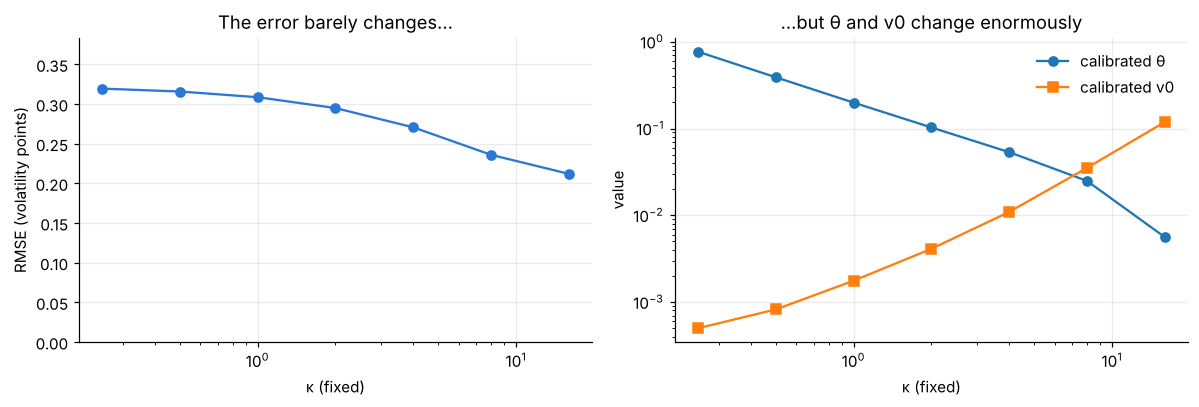

In [8]:
T_profile = min(cal["T"].unique(), key=lambda T: abs(T * 365 - 109))       # the maturity closest to 109 days
g = cal[cal["T"] == T_profile]                                             # its options
profile = []
for kappa in [0.25, 0.5, 1, 2, 4, 8, 16]:                                  # values of κ that we fix
    p, se, rmse, _ = calibrate_maturity(g, r, fixed={"kappa": kappa}, starts=[pg])   # we calibrate θ, ν, ρ, v0
    mean_var = p["theta"] + (p["v0"] - p["theta"]) * (1 - np.exp(-kappa * T_profile)) / (kappa * T_profile)
    profile.append(dict(kappa=kappa, rmse=100 * rmse, theta=p["theta"], nu=p["nu"], rho=p["rho"], v0=p["v0"],
                        mean_vol=100 * np.sqrt(mean_var)))                 # √(average variance), in points
profile = pd.DataFrame(profile)
print(f"Profile in κ, maturity of {round(T_profile * 365)} days:")
display(profile.round(4))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(profile["kappa"], profile["rmse"], "o-", color="#2a78d6")
ax[0].set_xscale("log"); ax[0].set_xlabel("κ (fixed)"); ax[0].set_ylabel("RMSE (volatility points)")
ax[0].set_ylim(0, 1.2 * profile["rmse"].max()); ax[0].set_title("The error barely changes...")
ax[1].plot(profile["kappa"], profile["theta"], "o-", label="calibrated θ")
ax[1].plot(profile["kappa"], profile["v0"], "s-", label="calibrated v0")
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xlabel("κ (fixed)"); ax[1].set_ylabel("value")
ax[1].set_title("...but θ and v0 change enormously"); ax[1].legend()
plt.tight_layout(); plt.savefig("fig_kappa_profile.png", dpi=150); plt.show()

## 5. Case B and case C: we fix the parameters that a single maturity does not identify

- **Case B:** κ and θ fixed (those of the global calibration); we calibrate **ν, ρ and v0** at each maturity. Here v0 plays the role of an "effective variance" that fits the level of each maturity.
- **Case C:** κ, θ **and v0** fixed; we calibrate only **ν and ρ**. It is the cleanest version: v0 is today's variance and, in theory, should not depend on the maturity.

If Heston with constant parameters were a good model, ν and ρ should come out **equal at all maturities** (within the standard errors). If they come out very different, the model would need parameters that depend on T. In the literature this is called *Heston with time-dependent parameters* (Mikhailov and Nögel, 2003; Benhamou, Gobet and Miri, 2010).

In [9]:
t0 = time.time()
caseB = calibrate_all(cal, r, fixed={"kappa": pg["kappa"], "theta": pg["theta"]}, starts=starts_from(pg), reference=pg)
caseC = calibrate_all(cal, r, fixed={"kappa": pg["kappa"], "theta": pg["theta"], "v0": pg["v0"]}, starts=starts_from(pg), reference=pg)
print(f"Time: {time.time() - t0:.0f} s")
print("Case B (κ, θ fixed):")
display(caseB[["days", "n", "rmse_global", "rmse", "nu", "se_nu", "rho", "se_rho", "v0", "se_v0", "feller_ratio", "at_limit"]].round(3))
print("Case C (κ, θ, v0 fixed):")
display(caseC[["days", "n", "rmse_global", "rmse", "nu", "se_nu", "rho", "se_rho", "feller_ratio", "at_limit"]].round(3))

Time: 325 s
Case B (κ, θ fixed):


,days,n,rmse_global,rmse,nu,se_nu,rho,se_rho,v0,se_v0,feller_ratio,at_limit
0,3,40,3.217,1.719,4.508,0.538,-0.312,0.106,0.012,0.001,0.036,
1,4,40,5.555,1.824,4.790,0.374,-0.554,0.075,0.011,0.001,0.032,
2,7,40,1.938,1.679,2.806,0.341,-0.453,0.084,0.008,0.001,0.094,
3,11,40,2.000,1.642,3.069,0.300,-0.449,0.080,0.009,0.001,0.078,
4,18,40,2.124,1.517,2.830,0.234,-0.530,0.060,0.011,0.001,0.092,
5,25,40,1.077,0.659,1.749,0.094,-0.567,0.033,0.013,0.001,0.241,
6,49,40,0.674,0.622,2.013,0.090,-0.609,0.026,0.011,0.001,0.182,
7,67,40,0.441,0.201,2.222,0.071,-0.481,0.021,0.015,0.001,0.149,
8,80,40,0.509,0.410,2.048,0.068,-0.632,0.018,0.011,0.001,0.176,
9,109,40,0.349,0.234,2.102,0.063,-0.614,0.013,0.009,0.001,0.167,


Case C (κ, θ, v0 fixed):


,days,n,rmse_global,rmse,nu,se_nu,rho,se_rho,feller_ratio,at_limit
0,3,40,3.217,1.803,4.548,0.566,-0.376,0.105,0.036,
1,4,40,5.555,1.885,5.000,0.343,-0.582,0.070,0.029,nu
2,7,40,1.938,1.810,2.768,0.342,-0.417,0.087,0.096,
3,11,40,2.000,1.662,3.045,0.297,-0.438,0.077,0.080,
4,18,40,2.124,1.548,2.916,0.242,-0.541,0.060,0.087,
5,25,40,1.077,0.923,1.545,0.107,-0.626,0.043,0.309,
6,49,40,0.674,0.668,1.928,0.083,-0.625,0.027,0.198,
7,67,40,0.441,0.355,1.731,0.047,-0.637,0.023,0.246,
8,80,40,0.509,0.439,1.991,0.065,-0.647,0.017,0.186,
9,109,40,0.349,0.234,2.122,0.032,-0.612,0.011,0.164,


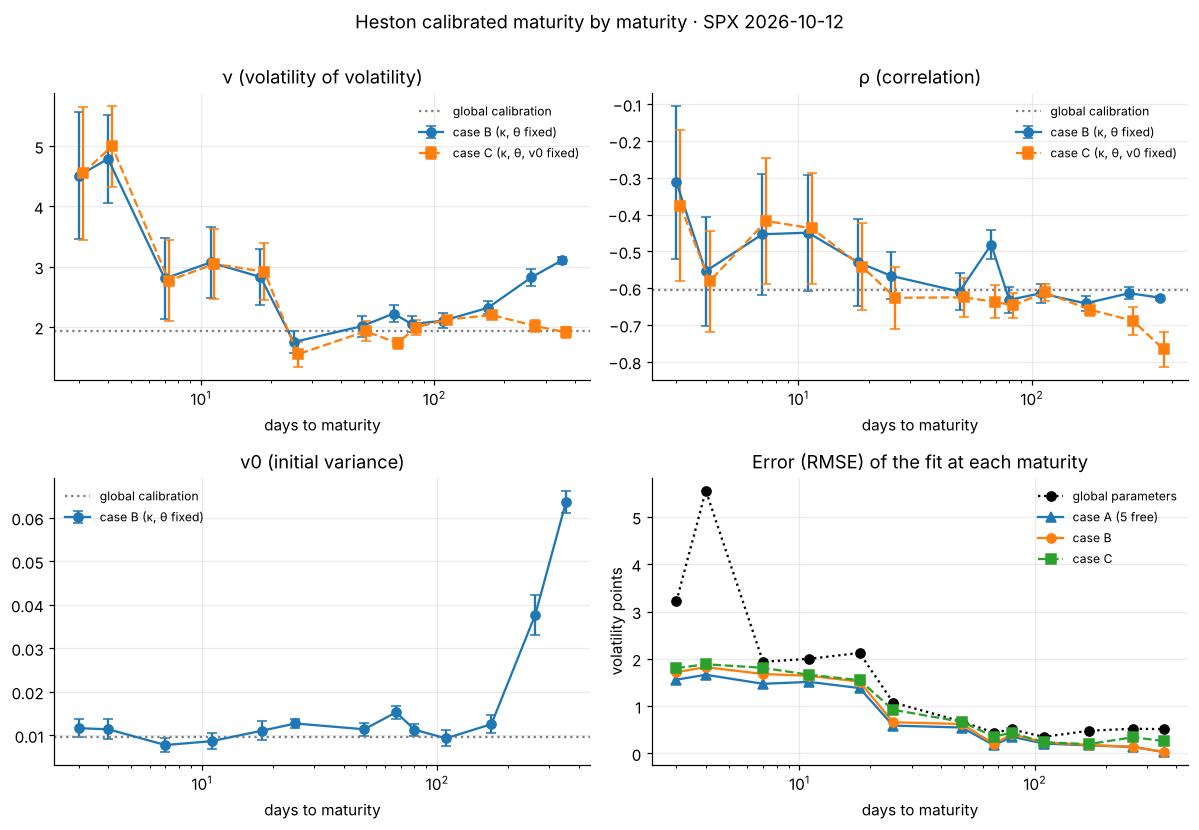

In [10]:
# Main plot: parameters as a function of maturity (logarithmic x axis), with 95% intervals (± 1.96 standard errors)
fig, ax = plt.subplots(2, 2, figsize=(11, 7.5))
for a, name, title in [(ax[0, 0], "nu", "ν (volatility of volatility)"), (ax[0, 1], "rho", "ρ (correlation)"),
                       (ax[1, 0], "v0", "v0 (initial variance)")]:
    a.errorbar(caseB["days"], caseB[name], yerr=1.96 * caseB["se_" + name], fmt="o-", capsize=3, label="case B (κ, θ fixed)")
    if name != "v0":                                                       # in case C, v0 is fixed: it makes no sense to plot it
        a.errorbar(caseC["days"] * 1.04, caseC[name], yerr=1.96 * caseC["se_" + name], fmt="s--", capsize=3,
                   label="case C (κ, θ, v0 fixed)")                        # (×1.04: small shift so that they do not overlap)
    a.axhline(pg[name], color="gray", ls=":", label="global calibration")  # global value as a horizontal line
    a.set_xscale("log"); a.set_xlabel("days to maturity"); a.set_title(title); a.legend(fontsize=8)
a = ax[1, 1]                                                               # fourth panel: error at each maturity
a.plot(caseB["days"], caseB["rmse_global"], "k:o", label="global parameters")
a.plot(caseA["days"], caseA["rmse"], "^-", label="case A (5 free)")
a.plot(caseB["days"], caseB["rmse"], "o-", label="case B")
a.plot(caseC["days"], caseC["rmse"], "s--", label="case C")
a.set_xscale("log"); a.set_xlabel("days to maturity"); a.set_ylabel("volatility points")
a.set_title("Error (RMSE) of the fit at each maturity"); a.legend(fontsize=8)
fig.suptitle(f"Heston calibrated maturity by maturity · SPX {DAY}", y=1.0)
plt.tight_layout(); plt.savefig("fig_parameters_vs_T.png", dpi=150); plt.show()

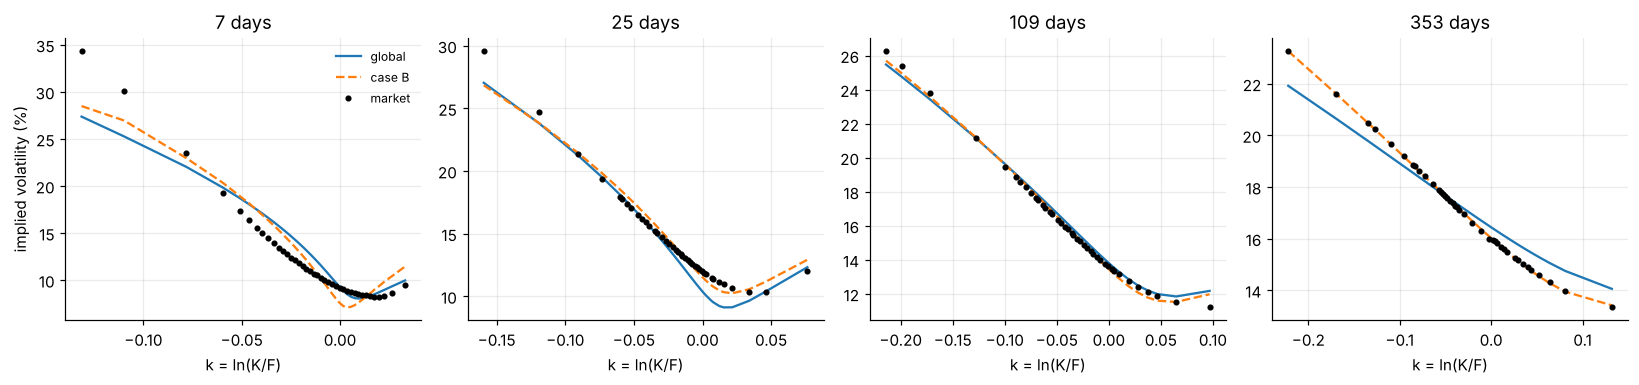

In [11]:
# Smiles of 4 maturities: market (dots), Heston with global parameters (line) and Heston with its own case B parameters (dashed)
fig, ax = plt.subplots(1, 4, figsize=(15, 3.6))
for a, target in zip(ax, [7, 25, 109, 353]):                               # approximate days of the 4 maturities
    T = min(cal["T"].unique(), key=lambda t: abs(t * 365 - target))        # the closest maturity
    g = cal[cal["T"] == T]
    F, K = g["F"].iloc[0], g["K"].values
    k = np.log(K / F)
    pB = caseB[caseB["T"] == T].iloc[0]                                    # case B row of this maturity
    for p, style, label in [(pg, "-", "global"), (pB, "--", "case B")]:
        prices = ht.heston_call_fwd(F, K, T, r, p["kappa"], p["theta"], p["nu"], p["rho"], p["v0"])
        a.plot(k, 100 * iv_bisection(prices, F, K, T, r), style, label=label)
    a.plot(k, 100 * g["iv"], "o", ms=3, color="k", label="market")
    a.set_title(f"{round(T * 365)} days"); a.set_xlabel("k = ln(K/F)")
ax[0].set_ylabel("implied volatility (%)"); ax[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig("fig_smiles_by_maturity.png", dpi=150); plt.show()

## 6. Does the pattern repeat on the other days?

A single day can be noisy. We repeat the global calibration and case B for **all the days** in `..\Data` up to the main day (7, 9 and 12 October). Two decisions:
- In case B we fix κ and θ at the values **of the main day for all days**. If each day used its own, the differences in ν(T) between days could come only from κ and θ being different, and we could not compare the curves.
- To save time, the global calibration of each day (which we do to see whether κ, θ, ... are stable from one day to the next) starts from a single starting point: the solution of the main day. (For 9 October this was checked with 4 different starting points, which give the same result.) If the pattern of ν(T) and ρ(T) is similar on all days, it is a feature of the market and not noise.

Available days: ['2026-10-07', '2026-10-09', '2026-10-12']
Time: 579 s
Global calibration of each day:


,day,kappa,theta,nu,rho,v0,rmse,feller_ratio
0,2026-10-07,10.8670,0.0377,1.8907,-0.5978,0.0082,1.5627,0.2290
1,2026-10-09,19.0794,0.0355,3.0704,-0.5744,0.0008,1.5022,0.1439
2,2026-10-12,9.5430,0.0386,1.9396,-0.6050,0.0096,2.0836,0.1960


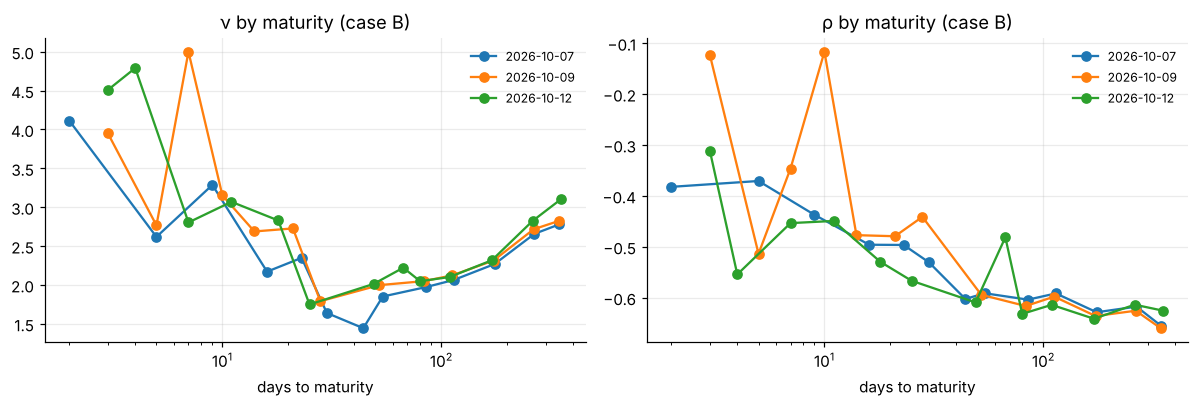

In [12]:
available_days = sorted(d for d in os.listdir(DATA_FOLDER)                     # data folders...
                        if len(d) == 10 and d <= DAY and os.path.exists(os.path.join(DATA_FOLDER, d, "market.csv")))  # ...complete ones (YYYY-MM-DD), up to the main day
print("Available days:", available_days)
t0 = time.time()
globals_by_day, caseB_by_day = [], {}
for d in available_days:
    if d == DAY:                                                           # the main day is already done
        pg_d, rmse_d, caseB_d = pg, rmse_global, caseB
    else:
        _, r_d, chain_d = load_day(d, show=False)                          # data of day d
        cal_d = ht.thin_chain(chain_d, max_per_T=40)
        pg_d, _, rmse_d = ht.calibrate(cal_d, r_d, starts=[[pg[n] for n in ht.PARAM_NAMES]], verbose=False)
        # κ and θ fixed at the values of the MAIN DAY (the same for all days), so that the curves are comparable
        caseB_d = calibrate_all(cal_d, r_d, fixed={"kappa": pg["kappa"], "theta": pg["theta"]}, starts=starts_from(pg))
    globals_by_day.append(dict(day=d, **pg_d, rmse=100 * rmse_d, feller_ratio=2 * pg_d["kappa"] * pg_d["theta"] / pg_d["nu"] ** 2))
    caseB_by_day[d] = caseB_d
print(f"Time: {time.time() - t0:.0f} s")
print("Global calibration of each day:")
display(pd.DataFrame(globals_by_day).round(4))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for d, table in caseB_by_day.items():
    ax[0].plot(table["days"], table["nu"], "o-", label=d)
    ax[1].plot(table["days"], table["rho"], "o-", label=d)
for a, title in zip(ax, ["ν by maturity (case B)", "ρ by maturity (case B)"]):
    a.set_xscale("log"); a.set_xlabel("days to maturity"); a.set_title(title); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig("fig_stability_days.png", dpi=150); plt.show()

## 7. Case D and case E: which parameter fits the *smile*, ν or ρ?

In case C two parameters are calibrated at each maturity, ν and ρ. To find out which of the two does the work, we leave only one free:

- **Case D:** κ, θ, v0 **and ρ** fixed at the global values; only **ν** is calibrated.
- **Case E:** κ, θ, v0 **and ν** fixed at the global values; only **ρ** is calibrated.

Each case is a restriction of case C (one free parameter fewer), so its error cannot be smaller than that of case C. And the global parameters also satisfy the restrictions of both cases, so the error cannot be larger than that of the global parameters either. The question is which of the two extremes each case gets close to.

Time: 27 s
RMSE error (volatility points) at each maturity, and the parameter calibrated in cases D and E:


,days,global,C (ν and ρ),D (only ν),ν in case D,E (only ρ),ρ in case E
0,3,3.217,1.803,1.976,3.822,2.913,-0.826
1,4,5.555,1.885,1.889,4.978,5.210,-0.747
2,7,1.938,1.810,1.880,2.297,1.933,-0.574
3,11,2.000,1.662,1.767,2.656,1.991,-0.648
4,18,2.124,1.548,1.574,2.772,2.060,-0.689
5,25,1.077,0.923,0.926,1.568,1.065,-0.567
6,49,0.674,0.668,0.673,1.960,0.668,-0.623
7,67,0.442,0.355,0.364,1.767,0.437,-0.586
8,80,0.509,0.440,0.471,2.082,0.443,-0.655
9,109,0.349,0.234,0.235,2.130,0.321,-0.643


Average over the maturities and percentage of the improvement of case C (with respect to the global parameters) that is achieved:


,global,C (ν and ρ),D (only ν),E (only ρ)
mean RMSE,1.49,0.93,0.99,1.38
% of the improvement of case C,0.00,100.00,89.93,19.32


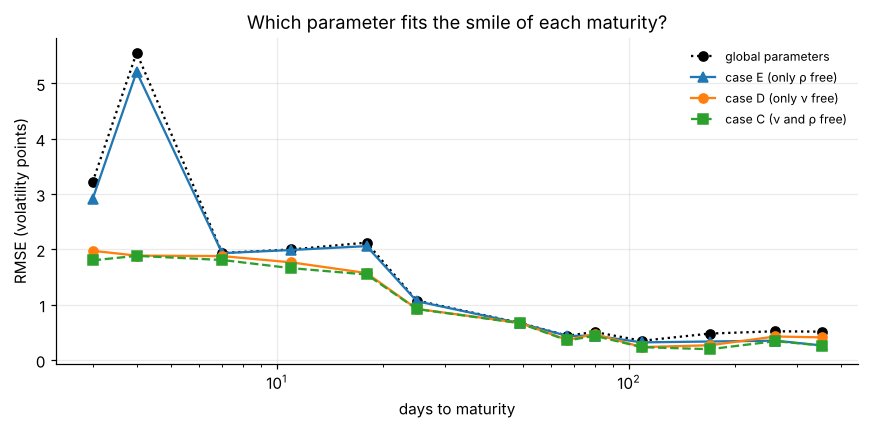

In [13]:
t0 = time.time()
fixed_C = {"kappa": pg["kappa"], "theta": pg["theta"], "v0": pg["v0"]}             # the fixed parameters of case C
caseD = calibrate_all(cal, r, fixed=dict(fixed_C, rho=pg["rho"]), starts=starts_from(pg), reference=pg)  # only ν free
caseE = calibrate_all(cal, r, fixed=dict(fixed_C, nu=pg["nu"]), starts=starts_from(pg), reference=pg)    # only ρ free
print(f"Time: {time.time() - t0:.0f} s")
comparison = pd.DataFrame({"days": caseC["days"], "global": caseC["rmse_global"], "C (ν and ρ)": caseC["rmse"],
                           "D (only ν)": caseD["rmse"], "ν in case D": caseD["nu"],
                           "E (only ρ)": caseE["rmse"], "ρ in case E": caseE["rho"]})
print("RMSE error (volatility points) at each maturity, and the parameter calibrated in cases D and E:")
display(comparison.round(3))
means = comparison[["global", "C (ν and ρ)", "D (only ν)", "E (only ρ)"]].mean()   # average of the 13 maturities
improvement = (means["global"] - means) / (means["global"] - means["C (ν and ρ)"]) * 100   # % of the improvement of case C
print("Average over the maturities and percentage of the improvement of case C (with respect to the global parameters) that is achieved:")
display(pd.DataFrame({"mean RMSE": means, "% of the improvement of case C": improvement}).T.round(2))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(comparison["days"], comparison["global"], "k:o", label="global parameters")
ax.plot(comparison["days"], comparison["E (only ρ)"], "^-", label="case E (only ρ free)")
ax.plot(comparison["days"], comparison["D (only ν)"], "o-", label="case D (only ν free)")
ax.plot(comparison["days"], comparison["C (ν and ρ)"], "s--", label="case C (ν and ρ free)")
ax.set_xscale("log"); ax.set_xlabel("days to maturity"); ax.set_ylabel("RMSE (volatility points)")
ax.set_title("Which parameter fits the smile of each maturity?"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("fig_cases_D_E.png", dpi=150); plt.show()

## 8. Conclusions

The numbers are those of the main day (12/10/2026, 13 maturities from 3 to 353 days, 2,171 options; 40 per maturity in the calibration) and, in conclusion 5, those of the three downloaded days.

### 1. A single maturity does not identify the five Heston parameters (case A and profile)

With the 5 parameters free, κ ends up at the upper bound (20) in 9 of the 13 maturities, θ at the lower bound (0.005) at maturities of 109 days or more, and ν at the upper bound (5) at those of 3 and 4 days. The standard errors of κ reach 911 and those of θ 210, while ρ always comes out between −0.38 and −0.63, with standard errors between 0.05 and 0.22.

The reason is the information contained in a maturity: basically three numbers (the level of the ATM volatility, the skew and the curvature) for five parameters. The level depends mostly on the expected average variance up to maturity, θ + (v0 − θ)(1 − e^(−κT))/(κT), which is **a single number** made of **three** parameters (κ, θ and v0): there are infinitely many combinations that give the same value. The asymmetry of the *smile*, on the other hand, depends mostly on ρ (together with ν), and that is why ρ is well determined.

The profile at 109 days shows it directly: when κ goes from 0.25 to 16 (64 times larger), the error only falls from 0.32 to 0.21 points, while θ falls from 0.77 to 0.0056 and v0 rises from 0.0005 to 0.119. The expected average volatility, instead, barely moves (from 16.85% to 17.06%): the data pin down the average variance, not its parts. That is why κ and θ must be estimated with several maturities at once (global calibration) and must be fixed when calibrating maturity by maturity (cases B to E).

### 2. ν and ρ change with maturity: Heston with constant parameters does not fit the whole surface (cases B and C)

- **ν** (case B) is 4.5–4.8 at 3–4 days, 2.8–3.1 between 7 and 18 days, has its minimum at 25 days (1.75), stays between 2.0 and 2.3 from 49 to 170 days and rises again to 2.8–3.1 at 261–353 days.
- **ρ** is −0.31 at 3 days and between −0.45 and −0.55 up to 18 days; from 25 days onwards it is stable, between −0.48 and −0.64 (around −0.6).
- **v0** (case B) is between 0.008 and 0.015 up to 170 days, but 0.038 at 261 days and 0.064 at 353. With κ and θ fixed, v0 acts as an "effective variance" that fits the level of the long maturities, where the ATM volatility rises to 15–16%.

The 95% intervals of ν at 25 days [1.57; 1.93] and at 353 days [3.05; 3.16] do not overlap in case B, and in case C those of 18 days [2.44; 3.39] and 25 days [1.34; 1.76] do not overlap either. Therefore, the hypothesis that ν is the same at all maturities is not compatible with the data: a Heston model with constant parameters cannot fit all maturities well at the same time. In the literature, the solution is a Heston model with time-dependent parameters (Mikhailov and Nögel, 2003; Benhamou, Gobet and Miri, 2010). The standard errors assume that the errors of the options are independent, which is not true in the market, so they must be taken as indicative; but the differences are much larger than the standard errors and the pattern repeats on the three days (conclusion 5).

### 3. Heston fails mostly at short maturities

With the global parameters, the error is 3.2 and 5.6 volatility points at 3 and 4 days, about 2 points up to 18 days, less than 1.1 points from 25 days onwards and about 0.5 points or less from 67 days onwards. But the most important thing is that, **even with its own parameters for each maturity** (case A, 5 free parameters), the error is still 1.4 to 1.7 points up to 18 days, against less than 0.6 from 25 days onwards. Therefore, at short maturities the problem is not only that a single set of parameters cannot fit all maturities: Heston, with any parameters, cannot reproduce the shape of the *smile* at very short horizons, with a very steep skew and a lot of curvature in the put wing (it can be seen in the 7-day *smiles* of section 5). It is the same phenomenon studied in the ATM skew notebook.

### 4. The parameter that fits each maturity is ν, not ρ (cases D and E)

Average error of the 13 maturities: 1.49 points with the global parameters, 0.93 in case C (ν and ρ free), 0.99 in case D (only ν) and 1.38 in case E (only ρ). Leaving only ν free achieves 90% of the improvement of case C; leaving only ρ free, 19%. The clearest case is the 4-day one: with ρ alone the error barely falls (from 5.56 to 5.21 points), and with ν alone it falls to 1.89, the same as with both. ρ only adds something at the extremes: at 3 days (from 1.98 to 1.80) and at the long maturities (at 353 days, from 0.41 to 0.26), where in case E ρ becomes more negative (−0.83 at 3 days, −0.75 at 353 days).

The interpretation: in Heston, the skew depends mostly on the product ρν, but ν also controls the curvature of the *smile*. By changing ν, both the skew and the curvature of each maturity can be fitted at the same time; by changing ρ, the *smile* is only tilted.

With ρ fixed (case D), ν is 3.8–5.0 at 3–4 days, 2.3–2.8 between 7 and 18 days, 1.57 at 25 days and between 1.8 and 2.3 from 49 to 353 days. The rise of ν at short maturities appears in all cases (B, C and D) and is therefore robust. The rise at long maturities, on the other hand, only appears in case B, where v0 is also free and the two parameters compensate each other; in cases C and D, ν stays around 2 at long maturities. It should not be interpreted as a property of the market.

### 5. The pattern repeats on the three days, but the global calibration of a single day is not stable

The ν(T) and ρ(T) curves of case B on 7, 9 and 12 October have the same shape (section 6). In the global calibration, θ (between 0.0355 and 0.0386) and ρ (between −0.574 and −0.605) are stable from one day to the next, but κ (10.87; 19.08; 9.54), ν (1.89; 3.07; 1.94) and v0 (0.0082; 0.0008; 0.0096) change a lot on day 9, with a similar error (1.56; 1.50; 2.08 points). It is the same identification problem of conclusion 1, now with all maturities at once: very different combinations of κ, ν and v0 fit almost equally well. It means that ρ and θ of a global calibration can be interpreted, but κ, ν and v0 of a single day must be interpreted with caution.

### 6. Reproducibility

Run on two different computers, the global calibration of 12/10 gives practically the same parameters (κ = 9.542 and 9.543; θ = 0.0386, ν = 1.9396, ρ = −0.605 and v0 = 0.0096 on both; error of 2.08 points). That of 7/10 (κ = 10.87, θ = 0.0377, ν = 1.89, ρ = −0.598, v0 = 0.0082; error of 1.56 points) is practically equal to that of the ATM skew notebook (κ = 10.97, θ = 0.0372, ν = 1.865, ρ = −0.5905, v0 = 0.0080; error of 1.56 points), which uses another download of the same close and a slightly different selection of maturities.

### 7. Links with the rest of the thesis

- **ATM skew.** In Heston, the short-term ATM skew tends to the constant ρν/(4√v0), while that of the market grows like T^(−α), with α ≈ 0.27, as maturity shrinks. With ρ and v0 given, the only way Heston has to imitate it is a larger ν the shorter the maturity, which is exactly what comes out in cases B, C and D (from 1.5–1.75 at 25 days to 4–5 at 3–4 days). It is the "maturity by maturity" version of the result of the ATM skew notebook.
- **Feller.** The Feller ratio 2κθ/ν² is between 0.03 and 0.24 in case B and between 0.03 and 0.31 in case C: the condition does not hold at any maturity, and even less at the short ones, where ν is larger. That is why all prices are computed by Fourier, which does not need the condition, and any check with Monte Carlo must be done with the QE scheme or with the exact simulation of the variance (`feller_monte_carlo.ipynb`).
- **Error in implied volatility and not in price divided by vega.** For the leftmost option of the 7-day maturity (k = −0.13), the exact error of the model is −7.0 points, but the approximation (model price − market price)/vega says −3.17. The approximation is a first-order Taylor expansion: it assumes that the price is linear in σ. For an option far out of the money and with a short maturity, the vega changes a lot with σ (with the model volatility, 27%, it is much smaller than with the market one, 34%), so dividing by the market vega reduces the error to less than half. That is why the global calibration, which uses this approximation, gives little weight to the wings of the short maturities, and that is why here we calibrate with the exact error.

### 8. The errors are ordered as they should be

At each maturity, error(A) ≤ error(B) ≤ error(C) ≤ error(D) ≤ error(global), and also error(C) ≤ error(E) ≤ error(global). Each case is a restriction of the previous case (one more parameter is fixed), and minimising over a smaller set cannot give a lower minimum; moreover, the global parameters satisfy all the restrictions. In the tables it holds at all maturities (at 261 and 353 days cases A and B coincide). If it ever did not hold, it would mean that the optimiser stopped at a local minimum. It happened while this notebook was being prepared (in case C, at 4 days, the error was 3.41 points instead of 1.89 with a single starting point), and that is why `starts_from` gives three starting points to each calibration.

### References

- Benhamou, E., Gobet, E. and Miri, M. (2010). Time dependent Heston model. *SIAM Journal on Financial Mathematics*, 1, 289–325.
- Gatheral, J. (2006). *The Volatility Surface: A Practitioner's Guide.* Wiley (chapter 3, the Heston model).
- Greene, W. H. *Econometric Analysis.* Pearson (chapter on non-linear regression: standard errors in non-linear least squares).
- Heston, S. L. (1993). A closed-form solution for options with stochastic volatility with applications to bond and currency options. *Review of Financial Studies*, 6(2), 327–343.
- Mikhailov, S. and Nögel, U. (2003). Heston's stochastic volatility model: implementation, calibration and some extensions. *Wilmott Magazine*.